In [10]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [16]:
CURRENT_DIR =Path.cwd()
if CURRENT_DIR.name == "nootbooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_PATH = PROJECT_ROOT /"data" / "processed" / "tickets_en.csv"

In [17]:
DATA_PATH.exists()

True

In [18]:
tickets = pd.read_csv(DATA_PATH)

tickets.shape

(16338, 4)

In [19]:
tickets.head()

,subject,body,queue,text
0,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...",Technical Support,"Account Disruption Dear Customer Support Team,..."
1,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Returns and Exchanges,Query About Smart Home System Integration Feat...
2,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",Billing and Payments,Inquiry Regarding Invoice Details Dear Custome...
3,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Sales and Pre-Sales,Question About Marketing Agency Software Compa...
4,Feature Query,"Dear Customer Support,\n\nI hope this message ...",Technical Support,"Feature Query Dear Customer Support,\n\nI hope..."


In [22]:
tickets.info()

<class 'pandas.DataFrame'>
RangeIndex: 16338 entries, 0 to 16337
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   subject  13731 non-null  str  
 1   body     16338 non-null  str  
 2   queue    16338 non-null  str  
 3   text     16338 non-null  str  
dtypes: str(4)
memory usage: 510.7 KB


In [26]:
#Queue distribution

queue_counts = tickets["queue"].value_counts()

queue_counts

queue
Technical Support                  4737
Product Support                    3073
Customer Service                   2410
IT Support                         1942
Billing and Payments               1595
Returns and Exchanges               820
Service Outages and Maintenance     664
Sales and Pre-Sales                 513
Human Resources                     348
General Inquiry                     236
Name: count, dtype: int64

In [27]:
queue_percentages = (
    tickets["queue"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

queue_percentages

queue
Technical Support                  28.99
Product Support                    18.81
Customer Service                   14.75
IT Support                         11.89
Billing and Payments                9.76
Returns and Exchanges               5.02
Service Outages and Maintenance     4.06
Sales and Pre-Sales                 3.14
Human Resources                     2.13
General Inquiry                     1.44
Name: proportion, dtype: float64

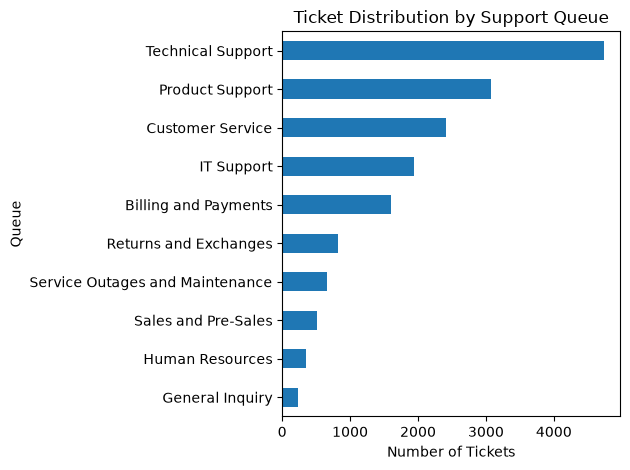

In [28]:
#visualization

queue_counts.sort_values().plot(kind="barh")

plt.title("Ticket Distribution by Support Queue")
plt.xlabel("Number of Tickets")
plt.ylabel("Queue")
plt.tight_layout()
plt.show()

In [31]:
#measure the imbalance

largest_class = queue_counts.max()
smallest_class = queue_counts.min()

imbalance_ratio = largest_class / smallest_class

imbalance_ratio

np.float64(20.072033898305083)

In [33]:
#Calculate the naive baseline

majority_baseline_accuracy = queue_counts.max() / len(tickets)

majority_baseline_accuracy

np.float64(0.28993756885787736)

In [34]:
print(f"Majority baseline accuracy: {majority_baseline_accuracy:.2%}")

Majority baseline accuracy: 28.99%


In [39]:
#inspect ticket length

tickets["char_counts"] = tickets['text'].str.len()


tickets["word_count"] = (
    tickets["text"]
    .str.split()
    .str.len()
)

In [40]:
tickets.columns

Index(['subject', 'body', 'queue', 'text', 'char_counts', 'word_count'], dtype='str')

In [42]:
tickets[["char_counts", "word_count"]].describe()

,char_counts,word_count
count,16338.000000,16338.000000
mean,405.538683,58.643041
std,179.688949,26.868554
min,19.000000,2.000000
25%,255.000000,36.000000
50%,416.000000,60.000000
75%,566.000000,82.000000
max,1189.000000,172.000000


In [43]:
tickets = tickets.rename(columns={"char_counts": "char_count"})

In [44]:
tickets[["char_count", "word_count"]].describe()

,char_count,word_count
count,16338.000000,16338.000000
mean,405.538683,58.643041
std,179.688949,26.868554
min,19.000000,2.000000
25%,255.000000,36.000000
50%,416.000000,60.000000
75%,566.000000,82.000000
max,1189.000000,172.000000


In [45]:
tickets.nlargest(
    5,
    "word_count"
)[["queue", "word_count", "text"]]

,queue,word_count,text
357,Returns and Exchanges,172,Request for Product Swap Dear Customer Support...
3796,Customer Service,172,Immediate Update Needed for SaaS Platform Dear...
1422,Customer Service,165,Urgent Update Needed for SaaS Platform Dear Cu...
4439,Billing and Payments,162,Assistance Needed with Integration Issue Dear ...
257,Product Support,154,Request for Complete Product Support Documenta...


In [46]:
tickets.nsmallest(
    5,
    "word_count"
)[["queue", "word_count", "text"]]

,queue,word_count,text
14648,Technical Support,2,ConcernregardingSystemInvestmentAnalytics Thec...
5974,Customer Service,3,Hello support team
995,Technical Support,4,Issue Encountered Assistance Needed
2944,General Inquiry,4,Problems with the server
3365,Technical Support,4,Several products are impacted


In [47]:
queue_length_stats = (
    tickets
    .groupby("queue")["word_count"]
    .agg(["count", "mean", "median", "max"])
    .sort_values("mean", ascending=False)
)

queue_length_stats

,count,mean,median,max
queue,,,,
General Inquiry,236,62.500000,70.0,104
Billing and Payments,1595,59.426332,61.0,162
Technical Support,4737,59.034410,61.0,153
Customer Service,2410,58.879668,61.0,172
IT Support,1942,58.294027,59.0,151
Product Support,3073,58.180931,59.0,154
Service Outages and Maintenance,664,58.000000,62.0,137
Sales and Pre-Sales,513,57.766082,62.0,124
Returns and Exchanges,820,57.689024,59.0,172


In [48]:
tickets[
    tickets["queue"] == "Billing and Payments"
][["text", "queue"]].head(5)

,text,queue
2,Inquiry Regarding Invoice Details Dear Custome...,Billing and Payments
18,"Query Dear Customer Support Team,\n\nI hope th...",Billing and Payments
24,Problem with Payment Billing Procedures Custom...,Billing and Payments
27,Inquiry for Comprehensive Billing Procedure De...,Billing and Payments
42,Discrepancies in Recent Billing Statement Dear...,Billing and Payments


## EDA Summary

- Dataset contains 16,338 English support tickets across 10 queues.
- The target distribution is strongly imbalanced.
- Technical Support is the largest class with 4,737 tickets.
- General Inquiry is the smallest class with 236 tickets.
- The largest class is approximately 20 times larger than the smallest.
- A majority-class classifier would achieve 28.99% accuracy.
- The median ticket length is 60 words.
- Because of class imbalance, Macro F1, precision, recall, and the confusion matrix should be considered alongside accuracy.